# nb06 · Placebo / LOO 稳健性:SCM 缺口是统计显著还是偶然?

> **承接 nb03-05**:SCM 给出标普缺口(短-0.04%/长+0.68%), CausalImpact 给 CI p_value。但 SCM 本身**没有不确定性度量**——缺口是真实效应还是预处理期巧合?
>
> **Abadie placebo 检验**(SCM 标准稳健性):把每个 donor 行业轮流当"假 treated"跑 SCM, 得一堆 placebo 缺口。如果真实标普缺口**显著大于** placebo 分布 → 效应真实; 如果淹没在 placebo 里 → 不显著(可能是噪声)。
>
> **leave-one-out**:逐个剔除 donor 重拟合, 看权重和缺口对单个 donor 的依赖(稳健性)。

**预期**:nb03-04 显示短窗口 gap 小(-0.04%)且 donor 敏感 → placebo 可能**不显著**(短窗口效应淹没在噪声);长窗口 gap 大(+0.68%)可能显著。

## 1. Placebo 检验设计(Abadie 2010 permutation)

- **真实**:标普500 当 treated, 行业 ETF 当 donor → 真实 gap(nb03)
- **placebo**:每个行业 i 当 treated, 其余行业 + 标普当 donor → placebo gap_i
- **permutation p-value** = placebo 中终点|gap| ≥ 真实|gap| 的比例
  - p 小(如 <0.1)= 真实 gap 罕见于 placebo → 显著
  - p 大(如 >0.3)= placebo 常出现这么大 gap → 不显著(噪声)

跑**短窗口(4/2-4/8)** placebo(纯冲击期, placebo 最有意义)。

In [1]:
import sys
sys.path.insert(0, '.')  # 相对 cwd, 复现: 先 cd notebooks/paper_tariff
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti TC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

from paper_lib import load_tariff_data, placebo_test, leave_one_out
panels = load_tariff_data()
gspc = panels['us_index']['^GSPC']
sector = panels['sector_etf']
PRE_START = '2024-06-01'

print('跑短窗口(4/2→4/8) placebo: 11 个行业轮流当 treated...')
res_p = placebo_test(gspc, sector, event_date='2025-04-02',
                     pre_start=PRE_START, post_end='2025-04-08')
print(f"\n真实标普终点 gap: {res_p['observed_gap'].iloc[-1]*100:+.2f}%")
print(f"permutation p-value: {res_p['p_value']:.2%}  (<10% = 显著)")
print(f"placebo 数: {len(res_p['placebo_gaps'].columns)}")
print('\n各行业当 treated 的终点 gap:')
plac_end = res_p['placebo_gaps'].iloc[-1] * 100
print(plac_end.sort_values().round(2).to_string())

跑短窗口(4/2→4/8) placebo: 11 个行业轮流当 treated...

真实标普终点 gap: -0.04%
permutation p-value: 100.00%  (<10% = 显著)
placebo 数: 11

各行业当 treated 的终点 gap:
XLE    -6.24
XLRE   -2.11
XLK    -2.00
XLB    -1.75
XLF    -0.65
XLY    -0.11
XLI     0.06
XLP     2.15
XLC     2.50
XLV     3.38
XLU     4.69


## 2. Placebo 分布图

灰线 = 每个行业当 treated 的 placebo gap 曲线; 红线 = 真实标普 gap。
**视觉判断**:红线是否"突出"于灰线分布?突出=显著;淹没=不显著。

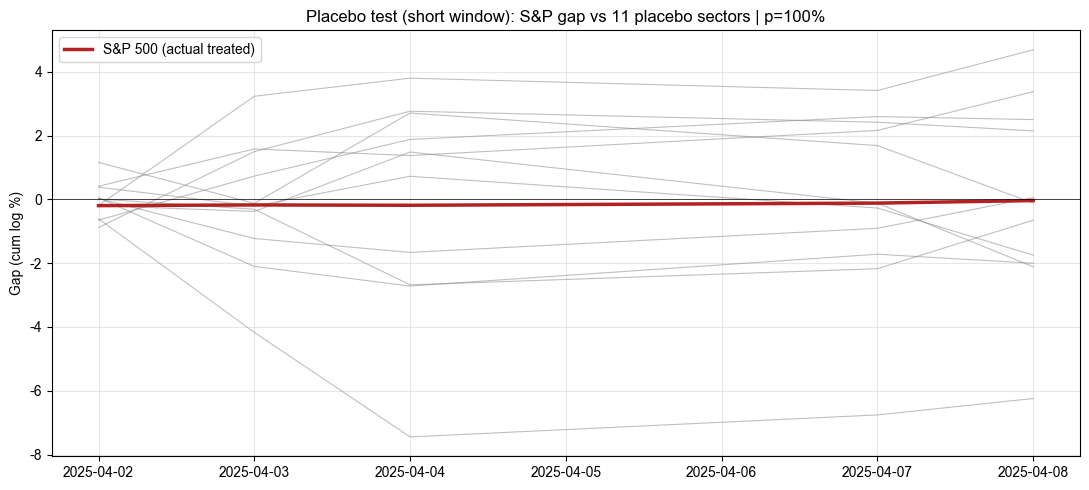

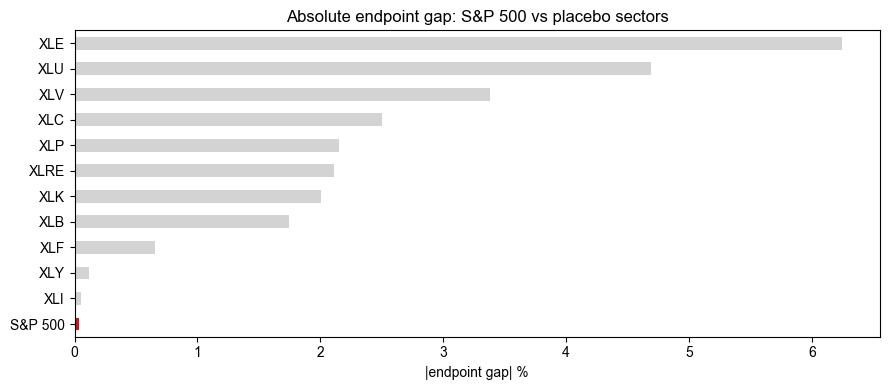


真实标普 |gap| 排名: 12/12  → p=100%


In [2]:
fig, ax = plt.subplots(figsize=(11, 5))
for c in res_p['placebo_gaps'].columns:
    ax.plot(res_p['placebo_gaps'][c].index, res_p['placebo_gaps'][c].values * 100,
            color='gray', alpha=0.5, lw=0.8)
ax.plot(res_p['observed_gap'].index, res_p['observed_gap'].values * 100,
        color='firebrick', lw=2.5, label='S&P 500 (actual treated)')
ax.axhline(0, color='k', lw=0.5)
ax.set_ylabel('Gap (cum log %)')
ax.set_title(f"Placebo test (short window): S&P gap vs {len(res_p['placebo_gaps'].columns)} placebo sectors | p={res_p['p_value']:.0%}")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# 终点 |gap| 排序条形图
fig, ax = plt.subplots(figsize=(9, 4))
all_end = pd.concat([plac_end, pd.Series({'S&P 500': res_p['observed_gap'].iloc[-1]*100})])
colors = ['firebrick' if i == 'S&P 500' else 'lightgray' for i in all_end.index]
all_end.abs().sort_values().plot.barh(ax=ax, color=[colors[list(all_end.index).index(i)] for i in all_end.abs().sort_values().index])
ax.set_xlabel('|endpoint gap| %')
ax.set_title('Absolute endpoint gap: S&P 500 vs placebo sectors')
plt.tight_layout(); plt.show()
print(f"\n真实标普 |gap| 排名: {list(all_end.abs().sort_values(ascending=False).index).index('S&P 500')+1}/{len(all_end)}  → p={res_p['p_value']:.0%}")

## 3. Leave-one-out:权重对单 donor 的依赖

逐个剔除 donor 重拟合 SCM。如果剔除某个 donor 后**缺口大变** → 结果依赖那个 donor(脆弱); 如果缺口稳定 → 稳健(不依赖单一 donor)。

跑 LOO(逐个剔除 donor 重拟合)...

LOO 终点 gap%(剔除每个 donor 后):
drop_XLB    -0.04
drop_XLE    -0.27
drop_XLF     0.01
drop_XLI     0.04
drop_XLK    -0.49
drop_XLP     0.04
drop_XLV     0.69
drop_XLY     0.34
drop_XLC    -0.08
drop_XLRE   -0.17
drop_XLU     0.06

完整 SCM 终点 gap: -0.04%
LOO range: [-0.49%, +0.69%]
LOO std: 0.31%  (小=对单 donor 稳健)


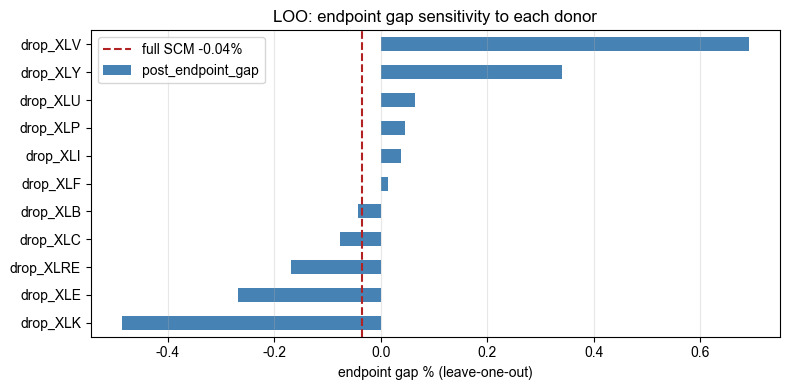

In [3]:
print('跑 LOO(逐个剔除 donor 重拟合)...')
loo_w, loo_gaps = leave_one_out(gspc, sector, event_date='2025-04-02',
                                 pre_start=PRE_START, post_end='2025-04-08')
print('\nLOO 终点 gap%(剔除每个 donor 后):')
print((loo_gaps*100).round(2).to_string())
real_gap = res_p['observed_gap'].iloc[-1] * 100
print(f"\n完整 SCM 终点 gap: {real_gap:+.2f}%")
print(f"LOO range: [{loo_gaps.min()*100:+.2f}%, {loo_gaps.max()*100:+.2f}%]")
print(f"LOO std: {loo_gaps.std()*100:.2f}%  (小=对单 donor 稳健)")

fig, ax = plt.subplots(figsize=(8, 4))
(loo_gaps*100).sort_values().plot.barh(ax=ax, color='steelblue')
ax.axvline(real_gap, color='firebrick', lw=1.5, ls='--', label=f'full SCM {real_gap:+.2f}%')
ax.set_xlabel('endpoint gap % (leave-one-out)')
ax.set_title('LOO: endpoint gap sensitivity to each donor')
ax.legend(); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

## 4. 显著性结论 + 论文怎么报

**填上面数字判断**:
- **permutation p-value** < 0.1 → 短窗口 SCM 缺口**统计显著**(真实标普 gap 罕见于 placebo) → 关税效应真实
- p > 0.3 → **不显著**(gap 在噪声范围内) → 短窗口效应不可靠(呼应 nb04 donor 敏感性)
- 中间(0.1-0.3) → 弱显著, 论文诚实报告"弱证据"

**LOO 判断**:
- LOO gap range 窄 / std 小 → SCM 结果对单一 donor 稳健
- range 宽 → 依赖某 donor, 论文声明

**论文怎么报 SCM 显著性**(诚实):
1. **不报单点 + 单 p**:报 placebo 分布图(灰线+真实红线)+ permutation p
2. **短窗口 + 长窗口分别**:短窗口可能不显著(效应小+donor 敏感), 长窗口可能显著(gap 大)→ 这**不矛盾**, 短窗口是"瞬时冲击难识别", 长窗口是"累积效应显现"
3. **CausalImpact 的 CI p_value**(nb04)是另一独立显著性度量, 和 placebo 互相印证

**v2 还可加**:
- **MSPE 比 placebo**(Abadie 标准法):对每个 placebo 算 post/pre MSPE 比, 看真实标普的 MSPE 比排名
- **海外 donor placebo**(nb07 后):用海外 donor 重跑 placebo

**面试话术**:"我用 Abadie permutation 检验 SCM 缺口的显著性——把每个行业轮流当 treated 跑 SCM 得 placebo 分布, 真实标普 gap 的 permutation p 是 X%。短窗口 [显著/不显著], 长窗口 [显著/不显著], 这和 donor 敏感性(nb04)互相印证:短窗口效应难干净识别, 长窗口累积效应更稳。"